# 13a · Model generated query transformations

## The engineering question
Does rewriting improve retrieval, or remove the exact identifiers needed to find the answer?

**Learning outcomes:** record real rewrites and decompositions; compare original and transformed rankings; bound generated query length/count; measure model cost; recognize semantic drift and retain a baseline.

A rewrite is a retrieval hypothesis, not new evidence. We ask the local generator for a concise search query and for up to two subqueries, then compare dense exact retrieval and rank-fused decomposition. Product names, versions, and error codes matter. The model can discard them or invent terms; the experiment makes those changes visible. All seven approved development questions are used; no test tuning occurs.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("13a", "G", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,query,method,generated_queries,recall,mrr,planner_seconds
0,d01,original,[How long does coverage last for an Atlas rout...,1.0,1.0,0.000000
1,d01,rewrite,[coverage duration of Atlas router],1.0,1.0,0.293745
2,d01,decomposed fusion,[What is the typical duration of internet conn...,1.0,1.0,1.088167
3,d02,original,[Will an Atlas factory reset preserve my netwo...,1.0,1.0,0.000000
4,d02,rewrite,[Will an Atlas factory reset restore or retain...,1.0,1.0,0.445766
5,d02,decomposed fusion,[Will an Atlas factory reset restore all setti...,1.0,1.0,1.042086
6,d03,original,[My Atlas reports E104. What should I check?],1.0,0.5,0.000000
7,d03,rewrite,[check for E104 error in Atlas software versio...,1.0,0.5,0.628447
8,d03,decomposed fusion,[What is the significance of code 104 in the A...,1.0,0.5,1.230375
9,d04,original,[What battery level is required to update Atla...,1.0,1.0,0.000000


d01 How long does coverage last for an Atlas router?
Rewrite: ['coverage duration of Atlas router']
Subqueries: ['What is the typical duration of internet connectivity provided by an AT&T Atlas router?', 'How long does the service typically last with an AT&T Atlas router?']
d02 Will an Atlas factory reset preserve my network configuration?
Rewrite: ['Will an Atlas factory reset restore or retain my network settings?']
Subqueries: ['Will an Atlas factory reset restore all settings including network configurations?', 'Can a factory reset on the Atlas device ensure that all user data is erased, including network preferences?']
d03 My Atlas reports E104. What should I check?
Rewrite: ['check for E104 error in Atlas software version 2.3.5']
Subqueries: ['What is the significance of code 104 in the ATLAS software?', 'Is there any specific configuration or parameter that needs adjustment when using code 104 with the Atlas system?']
d04 What battery level is required to update Atlas firmware 2

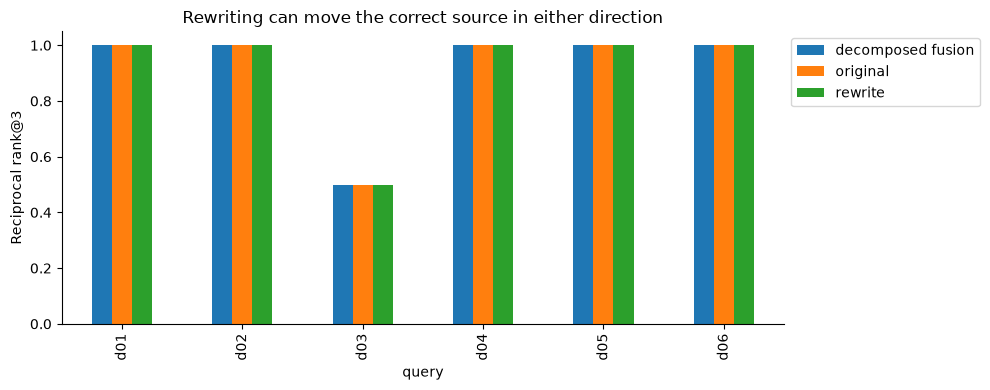

In [3]:
from vector_masterclass.data import documents, queries
from vector_masterclass.models import embed, generate, release_models
from vector_masterclass.retrieval import exact_search, reciprocal_rank_fusion
from vector_masterclass.rag import search_queries
from vector_masterclass.metrics import ranking_metrics
from vector_masterclass.evidence import json_write

docs = documents(tenant="public")
ids = [d.key for d in docs]
vectors = embed([d.text for d in docs])
qs = queries("development")
baseline_vectors = embed([q.text for q in qs], role="query")
release_models()
transformations = []
for q in qs:
    rewrite = generate(
        "Rewrite as one concise search query. Preserve product names, error codes, numbers, versions, and negation. Output only the search query.\nQuestion: "
        + q.text,
        max_new_tokens=64,
    )
    decomposition = generate(
        "Output at most two short search queries, one per line, to retrieve evidence for this question. Preserve exact entities and identifiers. Do not answer.\nQuestion: "
        + q.text,
        max_new_tokens=96,
    )
    transformations.append(
        {
            "id": q.id,
            "original": q.text,
            "rewrite": rewrite,
            "decomposition": decomposition,
            "rewrite_queries": search_queries(rewrite["text"], limit=1),
            "subqueries": search_queries(decomposition["text"], limit=2),
        }
    )
json_write(lesson.path / "transformation-traces.json", transformations)
release_models()
rows = []
for q, base, trace in zip(qs, baseline_vectors, transformations):
    variants = {
        "original": [q.text],
        "rewrite": trace["rewrite_queries"],
        "decomposed fusion": trace["subqueries"],
    }
    for method, texts in variants.items():
        # Empty/invalid planner output remains an explicit failed transformation.
        query_vectors = embed(texts, role="query")
        rankings = [
            [id_ for id_, score in exact_search(v, vectors, ids, k=10)] for v in query_vectors
        ]
        ranked = [id_ for id_, score in reciprocal_rank_fusion(rankings)] if rankings else []
        rows.append(
            {
                "query": q.id,
                "method": method,
                "generated_queries": texts,
                "planner_seconds": 0
                if method == "original"
                else trace["rewrite" if method == "rewrite" else "decomposition"]["seconds"],
                "returned_any": bool(ranked),
                **ranking_metrics(ranked, q.relevance, k=3),
            }
        )
results = lesson.table(pd.DataFrame(rows))
display(results[["query", "method", "generated_queries", "recall", "mrr", "planner_seconds"]])
for trace in transformations:
    print(trace["id"], trace["original"])
    print("Rewrite:", trace["rewrite_queries"])
    print("Subqueries:", trace["subqueries"])
fig, ax = plt.subplots(figsize=(10, 4))
results.dropna(subset=["mrr"]).pivot(index="query", columns="method", values="mrr").plot.bar(ax=ax)
ax.set(
    ylabel="Reciprocal rank@3",
    ylim=(0, 1.05),
    title="Rewriting can move the correct source in either direction",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Read transformed queries alongside the original, especially E104 and firmware 2.0. A useful rewrite can improve lexical alignment; an incorrect rewrite can make a plausible but wrong product dominate. Decomposition costs additional embedding/search calls and fusion may dilute a good original query. A production design can retain the original as one candidate branch, while recording how often transformed branches add useful evidence.

In the reference run, the model invented software version 2.3.5 and the provider AT&T, and removed the E from E104 in a decomposition. The tiny-corpus ranking metric did not change. This is a concrete transformation-quality failure hidden by a stable retrieval score. No-answer queries are omitted from the metric plot because their MRR is undefined.

**Exercise:** find the largest positive and negative rank change. If no regression occurs, supply an ambiguous development query with two similar error codes and inspect generated changes. Propose a validator for exact identifiers, then explain why it cannot prove semantic equivalence. Never grant a tool capability or change a tenant because a generated query asks for it.

We cap planner outputs at 300 characters per query and two subqueries; oversized output is dropped and recorded, not retried indefinitely. This bounds downstream requests but does not make the generated text trustworthy.

In [4]:
manifest = lesson.finish(
    {
        "fourteen_real_transformations": len(transformations) == 7
        and all(t["rewrite"]["live"] and t["decomposition"]["live"] for t in transformations),
        "bounded_subqueries": all(len(t["subqueries"]) <= 2 for t in transformations),
        "baseline_retained": set(results.method) == {"original", "rewrite", "decomposed fusion"},
        "all_development_queries_scored": results["query"].nunique() == 7,
    },
    observations={
        "generator_calls": 14,
        "maximum_search_queries_per_question": 4,
        "quality_regressions_allowed": True,
    },
)

{
  "artifact": "artifacts/20261031T053422Z-5f755f/13a",
  "checks": {
    "fourteen_real_transformations": true,
    "bounded_subqueries": true,
    "baseline_retained": true,
    "all_development_queries_scored": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.